In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
amazon = pd.read_csv('amz_uk_price_prediction.csv')
amazon.head()
amazon

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

In [3]:
crosstab = pd.crosstab(amazon['category'], amazon['isBestSeller'])
norm_crosstab = pd.crosstab(amazon['category'], amazon['isBestSeller'], normalize='index')

norm_crosstab.sort_values(by=True, ascending=False)
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


Best sellers seem to be just sligthly more prevalent for Grocery, Smart Home Security, Health & Personal care, Mobile Phone Accessories, etc.

In [4]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isbestseller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab)

chi2_statistic, chi2_p_value

(36540.20270061387, 0.0)

Chisquare value is large, which means strong deviation between observed and excpected (independance) values 
p is definitely < 0.05 so we can reject the null hypothesis, categories and isbestseller have a relationship. 

In [5]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab, method="cramer")

0.1222829439760564

Cramer is close to 0 so the relationship is not very strong

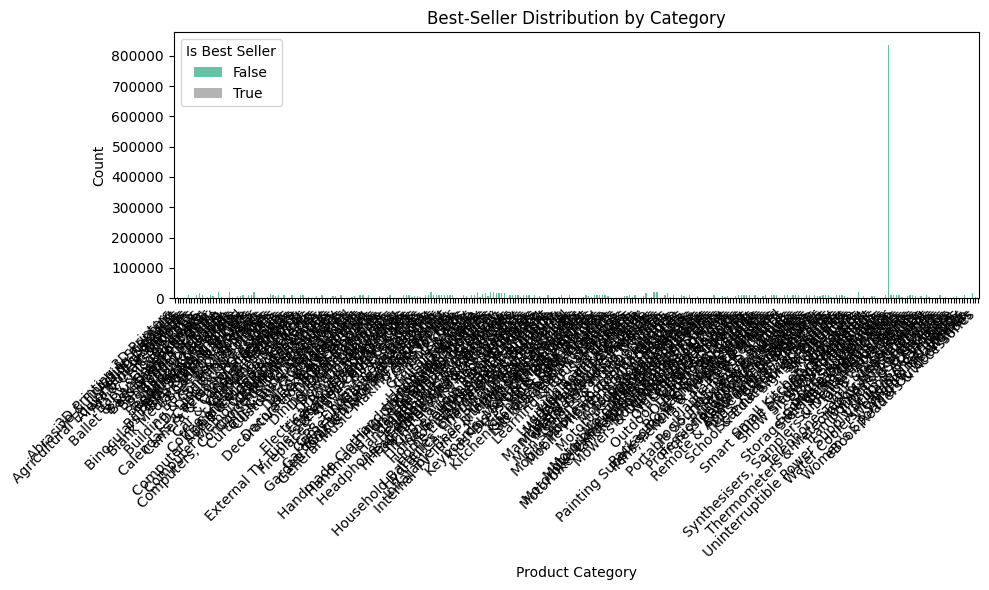

In [6]:
#Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

crosstab.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2')
plt.title("Best-Seller Distribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Count")
plt.legend(title="Is Best Seller")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

In [11]:
Q1 = amazon['price'].quantile(0.25)
Q3 = amazon['price'].quantile(0.75)
IQR = Q3 - Q1
    
    # Define bounds for the outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
amazon_subset = amazon[(amazon['price'] > lower_bound) & (amazon['price'] < upper_bound)]
    


In [12]:
amazon_subset

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [19]:
# Step 1: Get the top 20 categories by frequency
top20_categories = amazon_subset['category'].value_counts().head(20).index

# Step 2: Filter rows where category is in the top 20
amazon_subset_top20 = amazon_subset[amazon_subset['category'].isin(top20_categories)]

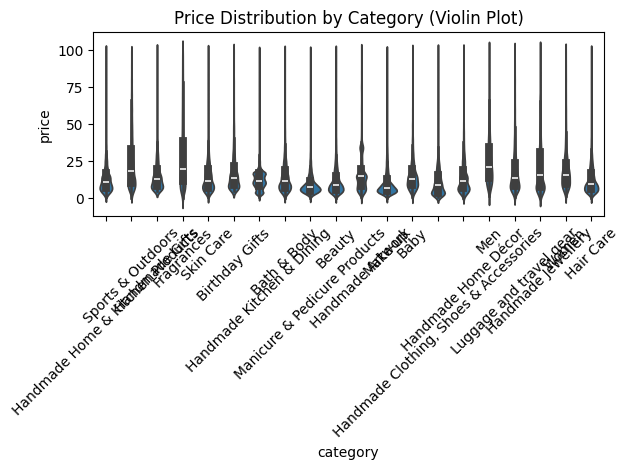

In [20]:
#Violin Plots:

sns.violinplot(data=amazon_subset_top20, x='category', y='price')

# Optional customization
plt.xticks(rotation=45)
plt.title("Price Distribution by Category (Violin Plot)")
plt.tight_layout()
plt.show()

In [22]:
amazon_subset.groupby(by='category')['price'].median().sort_values(ascending=False)

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

Tech categories seem to have the highest median price. 

In [23]:
#Bar charts
top10_categories = amazon_subset['category'].value_counts().head(10).index

amazon_subset_top10 = amazon_subset[amazon_subset['category'].isin(top10_categories)]

In [27]:
mean_prices = amazon_subset_top10.groupby(by='category')['price'].mean()

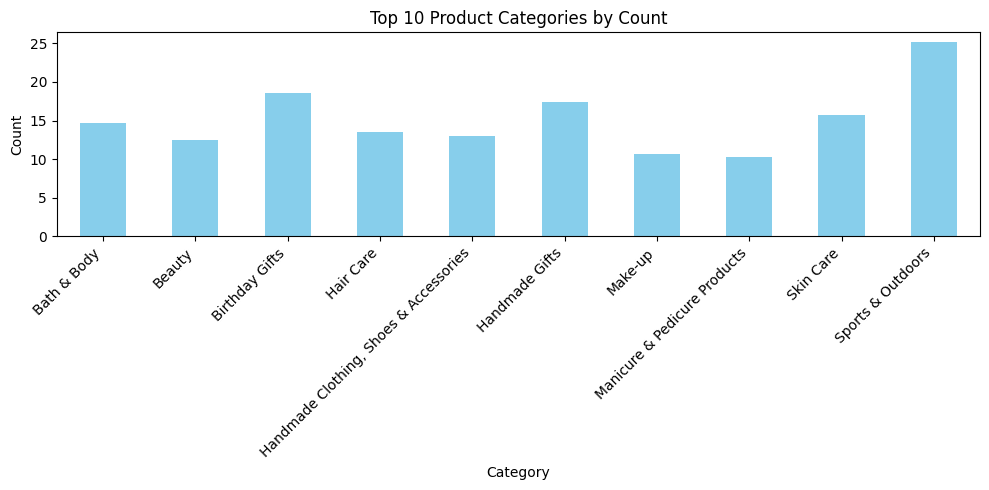

In [28]:
mean_prices.plot(kind='bar', figsize=(10, 5), color='skyblue')
plt.title("Top 10 Product Categories by Count")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [29]:
amazon_subset.groupby('category')['price'].mean().sort_values(ascending=False)

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

Montherboards is the category with the highest average price. 

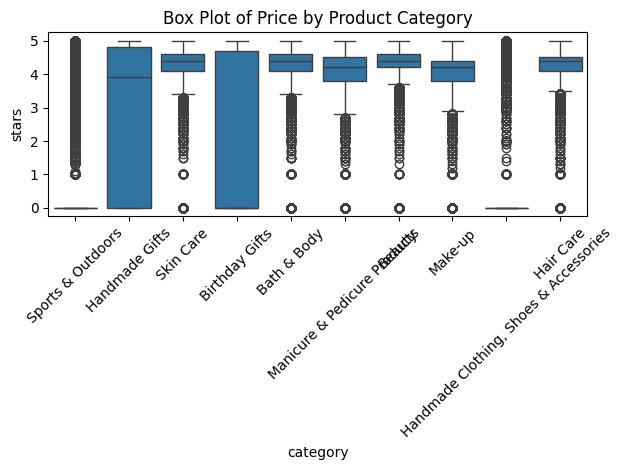

In [31]:
#Boxplots

sns.boxplot(data=amazon_subset_top10, x='category', y='stars')

plt.xticks(rotation=45)
plt.title("Box Plot of Price by Product Category")
plt.tight_layout()
plt.show()

In [33]:
amazon_subset.groupby('category')['stars'].median().sort_values(ascending=False)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

Computer memory tends to recieve the highest median ratings. 

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

In [36]:
correlation_pearson = amazon_subset['price'].corr(amazon_subset['stars'])
correlation_spearman = amazon_subset['price'].corr(amazon_subset['stars'], method='spearman')
correlation_pearson, correlation_spearman

(-0.07767299878181444, -0.06679697280768455)

The correlation coefficients are close to 0 and negative therefore suggest that there is close to no negative correlation relationship between price and ratings. 

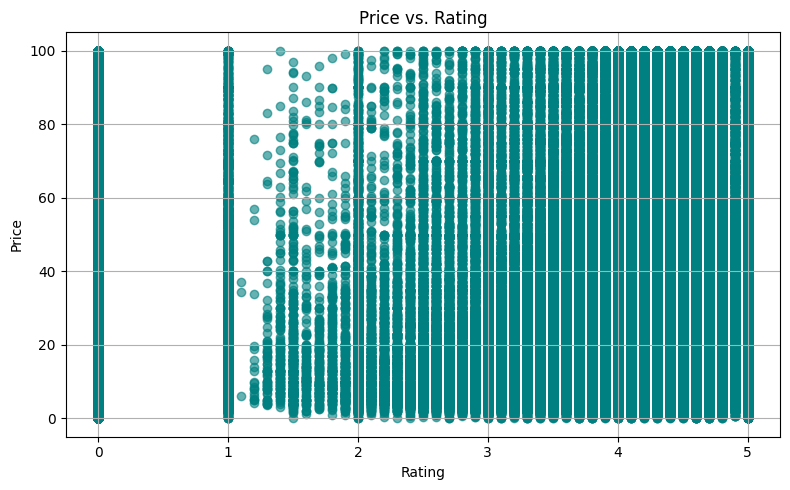

In [38]:
plt.figure(figsize=(8, 5))
plt.scatter(amazon_subset['stars'], amazon_subset['price'], alpha=0.6, color='teal')

plt.title("Price vs. Rating")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.grid(True)
plt.tight_layout()
plt.show()

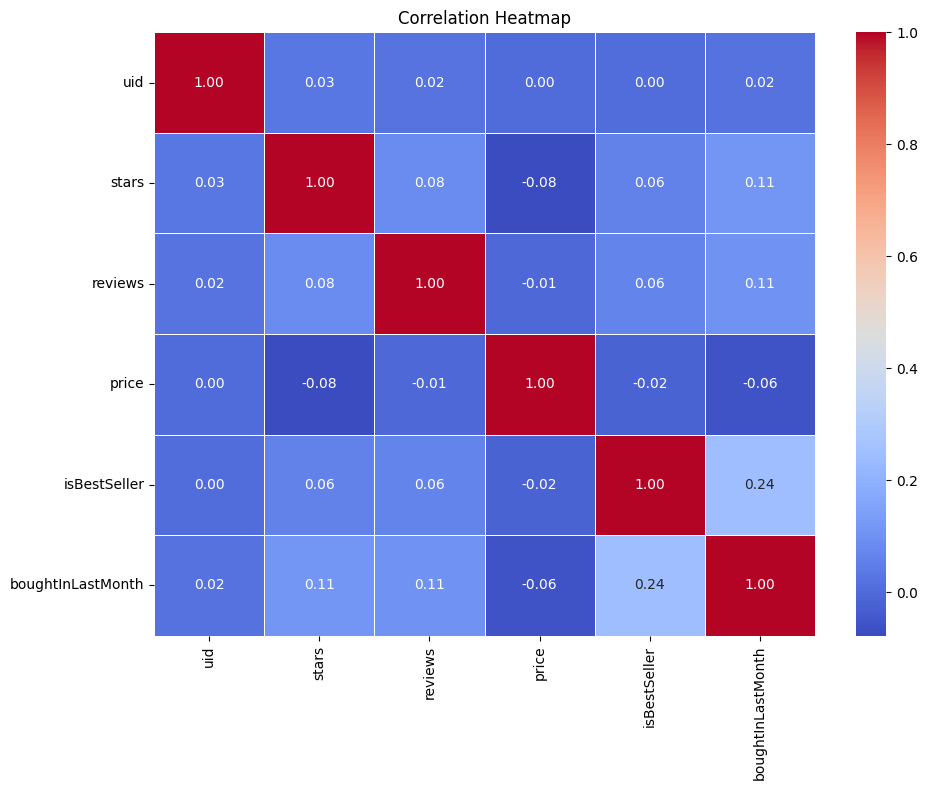

In [39]:
# Step 1: Compute correlation matrix (numeric columns only)
corr_matrix = amazon_subset.corr(numeric_only=True)

# Step 2: Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [43]:
!pip install statsmodels

  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/4b/e4/f9e96896278308e17dfd4f60a84826c48117674c980234ee38f59ab28a12/statsmodels-0.14.4-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/87/2b/b50d3d08ea0fc419c183a84210571eba005328efa62b6b98bc28e9ead32a/patsy-1.0.1-py2.py3-none-any.whl.metadata
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB 162.5 kB/s eta 0:01:01
   ---------------------------------------- 0.0/9.9 MB 186.2 kB/s eta 0:00:53
   ---------------------------------------- 0.0/9.9 MB 217.9 kB/s eta 0:00:46
   ---------------------------------------- 0.1/9.9 MB 280.5 kB/s eta 0:00:35
   ---------------------------------------- 0.1/9.9 MB 450

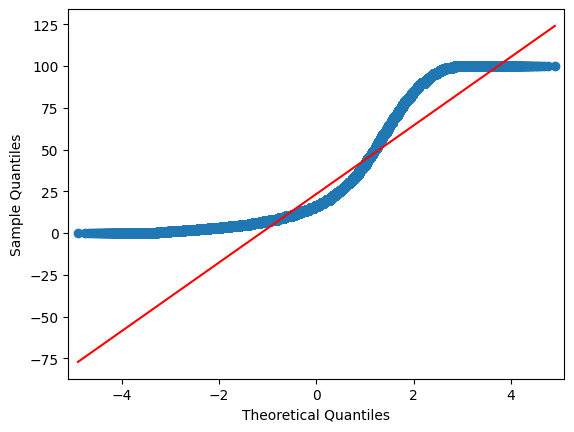

In [45]:

import statsmodels.api as sm

# Generating a Q-Q plot for 'Price' to check if its distribution follows a normal distribution
sm.qqplot(amazon_subset['price'], line='s');

prices are not normally distributed.